In [1]:
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

## Classifying IMDB movie reviews

In [8]:
url = "https://raw.githubusercontent.com/luisguiserrano/manning/master/Chapter_06_Logistic_Regression/IMDB_Dataset.csv"
movies = pd.read_csv(url)
movies.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [9]:
# Relabeling the 'sentiment' column as 0's and 1's
movies["sentiment"] = movies["sentiment"].map({"positive": 1, "negative": 0})
movies.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,1
2,I thought this was a wonderful way to spend ti...,1
3,Basically there's a family where a little boy ...,0
4,"Petter Mattei's ""Love in the Time of Money"" is...",1


________
#### Text Vectorization (Bag-of-Words)

- `CountVectorizer` selects the 2,000 most frequent words and ignores common English stop words (e.g., *the*, *is*, *and*).
- `fit_transform()` learns the vocabulary and converts each review into a numerical vector representing the frequency of each selected word. --> [2, 0, 1, 0, ...]
- `X` contains the numerical feature vectors.
- `y` contains the sentiment labels (positive/negative), which the model learns to predict.

In [10]:
# Create word features (limit to the 2000 most common words)
vectorizer = CountVectorizer(max_features=2000, stop_words="english")
X = vectorizer.fit_transform(movies["review"])
y = movies["sentiment"]

In [11]:
# Train logistic regression (linear model for interpretable weights)
model = LogisticRegression(max_iter=1000)
model.fit(X, y)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [12]:
# Get feature names (words) and their coefficients
feature_names = vectorizer.get_feature_names_out()
word_weights = model.coef_[0]  # Weights for positive sentiment

# Create DataFrame of words and their sentiment scores
word_sentiments = pd.DataFrame({
    'word': feature_names,
    'weight': word_weights
})

# Sort words by sentiment strength
most_positive = word_sentiments.sort_values('weight', ascending=False).head(10)
most_negative = word_sentiments.sort_values('weight').head(10)

In [13]:
print(most_positive)
print(most_negative)

             word    weight
1964  wonderfully  1.389643
735      funniest  1.176283
747           gem  1.168286
221   brilliantly  1.102917
1707       subtle  1.087836
1720       superb  1.045980
595     excellent  1.040486
686        finest  1.014097
449    delightful  1.002215
1853   underrated  0.971656
                word    weight
1921           waste -1.908884
491   disappointment -1.702126
1977           worst -1.581466
1009       laughable -1.473075
517         dreadful -1.445891
142            awful -1.442356
1858         unfunny -1.439198
1337          poorly -1.414668
1440       redeeming -1.407097
1756         tedious -1.389063


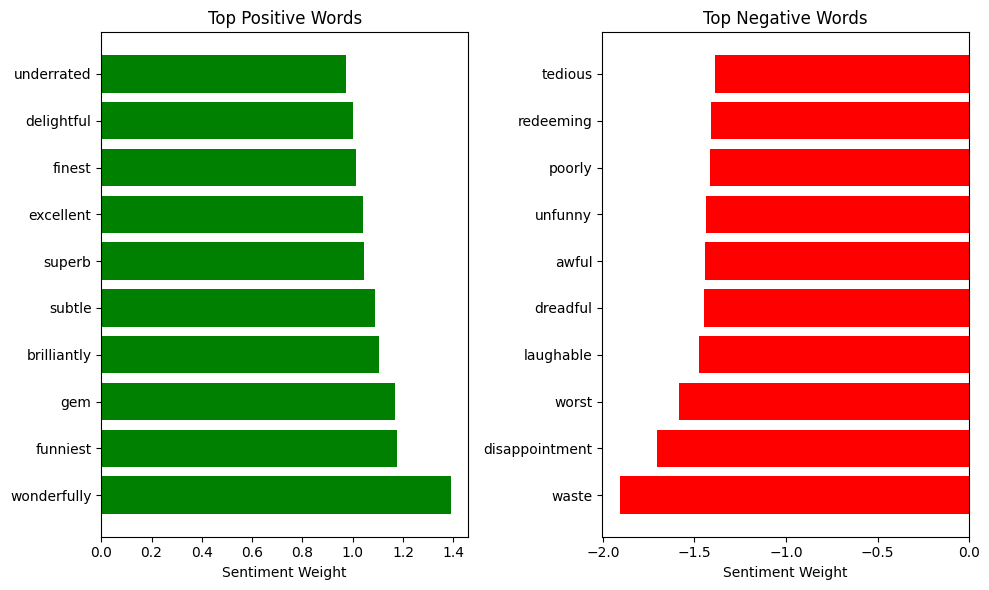

In [15]:
# Plot top positive/negative words
plt.figure(figsize=(10, 6))

# Positive words
plt.subplot(121)
plt.barh(most_positive['word'], most_positive['weight'], color='green')
plt.title('Top Positive Words')
plt.xlabel('Sentiment Weight')

# Negative words
plt.subplot(122)
plt.barh(most_negative['word'], most_negative['weight'], color='red')
plt.title('Top Negative Words')
plt.xlabel('Sentiment Weight')

plt.tight_layout()
plt.show()